# Part I - Prosper Loan Data Exploratory Analysis

## by Sathvika Kasam

## Introduction

> Introduce the dataset

## Preliminary Wrangling

In [2]:
# import all packages and set plots to be embedded inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline

# Set a consistent visual style for the plots
sns.set_style("whitegrid")

# Make pandas display more columns when inspecting the dataset
pd.set_option("display.max_columns", None)

### What is the structure of your dataset?

> The Prosper Loan dataset contains 113,937 loan records and 81 variables. Each row represents an individual loan, while the columns contain information about the loan characteristics, borrower demographics, credit history, loan status, and financial information. The dataset contains both numerical and categorical variables. Important numerical variables include loan amount, borrower interest rate, borrower income, credit score, and debt-to-income ratio, while categorical variables include loan status, employment status, home ownership, and loan purpose.

### What is/are the main feature(s) of interest in your dataset?

> The main features of interest are BorrowerRate, LoanOriginalAmount, and LoanStatus. BorrowerRate represents the interest rate assigned to a loan, LoanOriginalAmount represents the amount originally borrowed, and LoanStatus describes the current status of the loan. I am particularly interested in understanding how borrower characteristics and loan characteristics are related to interest rates and loan outcomes.

### What features in the dataset do you think will help support your investigation into your feature(s) of interest?

> Several features can help investigate the main features of interest. CreditScoreRangeLower and CreditScoreRangeUpper can help examine the relationship between creditworthiness and borrower interest rates. ProsperScore provides a risk score that can be compared with interest rates and loan status. DebtToIncomeRatio can help investigate the relationship between a borrower's financial obligations and loan characteristics. IncomeRange, EmploymentStatus, and HomeOwner can provide information about borrower financial circumstances. LoanTerm, LoanPurpose, and LoanOriginalAmount can help explain differences in interest rates and loan outcomes.

In [4]:
# Load the Prosper Loan dataset
df = pd.read_csv("prosperLoanData.csv")

In [5]:
# Display the first five rows
df.head()

,ListingKey,ListingNumber,ListingCreationDate,CreditGrade,Term,LoanStatus,ClosedDate,BorrowerAPR,BorrowerRate,LenderYield,EstimatedEffectiveYield,EstimatedLoss,EstimatedReturn,ProsperRating (numeric),ProsperRating (Alpha),ProsperScore,ListingCategory (numeric),BorrowerState,Occupation,EmploymentStatus,EmploymentStatusDuration,IsBorrowerHomeowner,CurrentlyInGroup,GroupKey,DateCreditPulled,CreditScoreRangeLower,CreditScoreRangeUpper,FirstRecordedCreditLine,CurrentCreditLines,OpenCreditLines,TotalCreditLinespast7years,OpenRevolvingAccounts,OpenRevolvingMonthlyPayment,InquiriesLast6Months,TotalInquiries,CurrentDelinquencies,AmountDelinquent,DelinquenciesLast7Years,PublicRecordsLast10Years,PublicRecordsLast12Months,RevolvingCreditBalance,BankcardUtilization,AvailableBankcardCredit,TotalTrades,TradesNeverDelinquent (percentage),TradesOpenedLast6Months,DebtToIncomeRatio,IncomeRange,IncomeVerifiable,StatedMonthlyIncome,LoanKey,TotalProsperLoans,TotalProsperPaymentsBilled,OnTimeProsperPayments,ProsperPaymentsLessThanOneMonthLate,ProsperPaymentsOneMonthPlusLate,ProsperPrincipalBorrowed,ProsperPrincipalOutstanding,ScorexChangeAtTimeOfListing,LoanCurrentDaysDelinquent,LoanFirstDefaultedCycleNumber,LoanMonthsSinceOrigination,LoanNumber,LoanOriginalAmount,LoanOriginationDate,LoanOriginationQuarter,MemberKey,MonthlyLoanPayment,LP_CustomerPayments,LP_CustomerPrincipalPayments,LP_InterestandFees,LP_ServiceFees,LP_CollectionFees,LP_GrossPrincipalLoss,LP_NetPrincipalLoss,LP_NonPrincipalRecoverypayments,PercentFunded,Recommendations,InvestmentFromFriendsCount,InvestmentFromFriendsAmount,Investors
0,1021339766868145413AB3B,193129,2007-08-26 19:09:29.263000000,C,36,Completed,2009-08-14 00:00:00,0.16516,0.1580,0.1380,NaN,NaN,NaN,NaN,NaN,NaN,0,CO,Other,Self-employed,2.0,True,True,NaN,2007-08-26 18:41:46.780000000,640.0,659.0,2001-10-11 00:00:00,5.0,4.0,12.0,1,24.0,3.0,3.0,2.0,472.0,4.0,0.0,0.0,0.0,0.00,1500.0,11.0,0.81,0.0,0.17,"$25,000-49,999",True,3083.333333,E33A3400205839220442E84,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,78,19141,9425,2007-09-12 00:00:00,Q3 2007,1F3E3376408759268057EDA,330.43,11396.14,9425.00,1971.14,-133.18,0.0,0.0,0.0,0.0,1.0,0,0,0.0,258
1,10273602499503308B223C1,1209647,2014-02-27 08:28:07.900000000,NaN,36,Current,NaN,0.12016,0.0920,0.0820,0.07960,0.0249,0.05470,6.0,A,7.0,2,CO,Professional,Employed,44.0,False,False,NaN,2014-02-27 08:28:14,680.0,699.0,1996-03-18 00:00:00,14.0,14.0,29.0,13,389.0,3.0,5.0,0.0,0.0,0.0,1.0,0.0,3989.0,0.21,10266.0,29.0,1.00,2.0,0.18,"$50,000-74,999",True,6125.000000,9E3B37071505919926B1D82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,134815,10000,2014-03-03 00:00:00,Q1 2014,1D13370546739025387B2F4,318.93,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,1.0,0,0,0.0,1
2,0EE9337825851032864889A,81716,2007-01-05 15:00:47.090000000,HR,36,Completed,2009-12-17 00:00:00,0.28269,0.2750,0.2400,NaN,NaN,NaN,NaN,NaN,NaN,0,GA,Other,Not available,NaN,False,True,783C3371218786870A73D20,2007-01-02 14:09:10.060000000,480.0,499.0,2002-07-27 00:00:00,NaN,NaN,3.0,0,0.0,0.0,1.0,1.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.06,Not displayed,True,2083.333333,6954337960046817851BCB2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,86,6466,3001,2007-01-17 00:00:00,Q1 2007,5F7033715035555618FA612,123.32,4186.63,3001.00,1185.63,-24.20,0.0,0.0,0.0,0.0,1.0,0,0,0.0,41
3,0EF5356002482715299901A,658116,2012-10-22 11:02:35.010000000,NaN,36,Current,NaN,0.12528,0.0974,0.0874,0.08490,0.0249,0.06000,6.0,A,9.0,16,GA,Skilled Labor,Employed,113.0,True,False,NaN,2012-10-22 11:02:32,800.0,819.0,1983-02-28 00:00:00,5.0,5.0,29.0,7,115.0,0.0,1.0,4.0,10056.0,14.0,0.0,0.0,1444.0,0.04,30754.0,26.0,0.76,0.0,0.15,"$25,000-49,999",True,2875.000000,A0393664465886295619C51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,16,77296,10000,2012-11-01 00:00:00,Q4 2012,9ADE356069835475068C6D2,321.45,5143.20,4091.09,1052.11,-108.01,0.0,0.0,0.0,0.0,1.0,0,0,0.0,158
4,0F023589499656230C5E3E2,909464,2013-09-14 18:38:39.097000000,NaN,36,Current,NaN,0.24614,0.2085,0.1985,0.18316,0.0925,0.09066,3.0,D,4.0,2,MN

In [6]:
# Check the number of rows and columns
df.shape

(113937, 81)

In [7]:
# Display all column names
df.columns.tolist()

['ListingKey',
 'ListingNumber',
 'ListingCreationDate',
 'CreditGrade',
 'Term',
 'LoanStatus',
 'ClosedDate',
 'BorrowerAPR',
 'BorrowerRate',
 'LenderYield',
 'EstimatedEffectiveYield',
 'EstimatedLoss',
 'EstimatedReturn',
 'ProsperRating (numeric)',
 'ProsperRating (Alpha)',
 'ProsperScore',
 'ListingCategory (numeric)',
 'BorrowerState',
 'Occupation',
 'EmploymentStatus',
 'EmploymentStatusDuration',
 'IsBorrowerHomeowner',
 'CurrentlyInGroup',
 'GroupKey',
 'DateCreditPulled',
 'CreditScoreRangeLower',
 'CreditScoreRangeUpper',
 'FirstRecordedCreditLine',
 'CurrentCreditLines',
 'OpenCreditLines',
 'TotalCreditLinespast7years',
 'OpenRevolvingAccounts',
 'OpenRevolvingMonthlyPayment',
 'InquiriesLast6Months',
 'TotalInquiries',
 'CurrentDelinquencies',
 'AmountDelinquent',
 'DelinquenciesLast7Years',
 'PublicRecordsLast10Years',
 'PublicRecordsLast12Months',
 'RevolvingCreditBalance',
 'BankcardUtilization',
 'AvailableBankcardCredit',
 'TotalTrades',
 'TradesNeverDelinquent (p

In [8]:
# Display the data type of each variable
df.dtypes

ListingKey                      object
ListingNumber                    int64
ListingCreationDate             object
CreditGrade                     object
Term                             int64
                                ...   
PercentFunded                  float64
Recommendations                  int64
InvestmentFromFriendsCount       int64
InvestmentFromFriendsAmount    float64
Investors                        int64
Length: 81, dtype: object

In [9]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113937 entries, 0 to 113936
Data columns (total 81 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   ListingKey                           113937 non-null  object 
 1   ListingNumber                        113937 non-null  int64  
 2   ListingCreationDate                  113937 non-null  object 
 3   CreditGrade                          28953 non-null   object 
 4   Term                                 113937 non-null  int64  
 5   LoanStatus                           113937 non-null  object 
 6   ClosedDate                           55089 non-null   object 
 7   BorrowerAPR                          113912 non-null  float64
 8   BorrowerRate                         113937 non-null  float64
 9   LenderYield                          113937 non-null  float64
 10  EstimatedEffectiveYield              84853 non-null   float64
 11  EstimatedLoss

In [17]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display only columns that contain missing values
missing_values[missing_values > 0].sort_values(ascending=False)

GroupKey                               100596
LoanFirstDefaultedCycleNumber           96985
ScorexChangeAtTimeOfListing             95009
ProsperPrincipalOutstanding             91852
ProsperPrincipalBorrowed                91852
ProsperPaymentsOneMonthPlusLate         91852
ProsperPaymentsLessThanOneMonthLate     91852
OnTimeProsperPayments                   91852
TotalProsperPaymentsBilled              91852
TotalProsperLoans                       91852
CreditGrade                             84984
ClosedDate                              58848
EstimatedEffectiveYield                 29084
EstimatedLoss                           29084
EstimatedReturn                         29084
ProsperRating (numeric)                 29084
ProsperRating (Alpha)                   29084
ProsperScore                            29084
DebtToIncomeRatio                        8554
EmploymentStatusDuration                 7625
AmountDelinquent                         7622
BankcardUtilization               

In [18]:
# Generate descriptive statistics for numerical variables
df.describe()

,ListingNumber,Term,BorrowerAPR,BorrowerRate,LenderYield,EstimatedEffectiveYield,EstimatedLoss,EstimatedReturn,ProsperRating (numeric),ProsperScore,ListingCategory (numeric),EmploymentStatusDuration,CreditScoreRangeLower,CreditScoreRangeUpper,CurrentCreditLines,OpenCreditLines,TotalCreditLinespast7years,OpenRevolvingAccounts,OpenRevolvingMonthlyPayment,InquiriesLast6Months,TotalInquiries,CurrentDelinquencies,AmountDelinquent,DelinquenciesLast7Years,PublicRecordsLast10Years,PublicRecordsLast12Months,RevolvingCreditBalance,BankcardUtilization,AvailableBankcardCredit,TotalTrades,TradesNeverDelinquent (percentage),TradesOpenedLast6Months,DebtToIncomeRatio,StatedMonthlyIncome,TotalProsperLoans,TotalProsperPaymentsBilled,OnTimeProsperPayments,ProsperPaymentsLessThanOneMonthLate,ProsperPaymentsOneMonthPlusLate,ProsperPrincipalBorrowed,ProsperPrincipalOutstanding,ScorexChangeAtTimeOfListing,LoanCurrentDaysDelinquent,LoanFirstDefaultedCycleNumber,LoanMonthsSinceOrigination,LoanNumber,LoanOriginalAmount,MonthlyLoanPayment,LP_CustomerPayments,LP_CustomerPrincipalPayments,LP_InterestandFees,LP_ServiceFees,LP_CollectionFees,LP_GrossPrincipalLoss,LP_NetPrincipalLoss,LP_NonPrincipalRecoverypayments,PercentFunded,Recommendations,InvestmentFromFriendsCount,InvestmentFromFriendsAmount,Investors
count,1.139370e+05,113937.000000,113912.000000,113937.000000,113937.000000,84853.000000,84853.000000,84853.000000,84853.000000,84853.000000,113937.000000,106312.000000,113346.000000,113346.000000,106333.000000,106333.000000,113240.000000,113937.00000,113937.000000,113240.000000,112778.000000,113240.000000,106315.000000,112947.000000,113240.000000,106333.000000,1.063330e+05,106333.000000,106393.000000,106393.000000,106393.000000,106393.000000,105383.000000,1.139370e+05,22085.000000,22085.000000,22085.000000,22085.000000,22085.000000,22085.000000,22085.000000,18928.000000,113937.000000,16952.000000,113937.000000,113937.000000,113937.00000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000,113937.000000
mean,6.278857e+05,40.830248,0.218828,0.192764,0.182701,0.168661,0.080306,0.096068,4.072243,5.950067,2.774209,96.071582,685.567731,704.567731,10.317192,9.260164,26.754539,6.96979,398.292161,1.435085,5.584405,0.592052,984.507059,4.154984,0.312646,0.015094,1.759871e+04,0.561309,11210.225447,23.230034,0.885897,0.802327,0.275947,5.608026e+03,1.421100,22.934345,22.271949,0.613629,0.048540,8472.311961,2930.313906,-3.223214,152.816539,16.268464,31.896882,69444.474271,8337.01385,272.475783,4183.079489,3105.536588,1077.542901,-54.725641,-14.242698,700.446342,681.420499,25.142686,0.998584,0.048027,0.023460,16.550751,80.475228
std,3.280762e+05,10.436212,0.080364,0.074818,0.074516,0.068467,0.046764,0.030403,1.673227,2.376501,3.996797,94.480605,66.458275,66.458275,5.457866,5.022644,13.637871,4.63097,447.159711,2.437507,6.429946,1.978707,7158.270157,10.160216,0.727868,0.154092,3.293640e+04,0.317918,19818.361309,11.871311,0.148179,1.097637,0.551759,7.478497e+03,0.764042,19.249584,18.830425,2.446827,0.556285,7395.507650,3806.635075,50.063567,466.320254,9.005898,29.974184,38930.479610,6245.80058,192.697812,4790.907234,4069.527670,1183.414168,60.675425,109.232758,2388.513831,2357.167068,275.657937,0.017919,0.332353,0.232412,294.545422,103.239020
min,4.000000e+00,12.000000,0.006530,0.000000,-0.010000,-0.182700,0.004900,-0.182700,1.000000,1.000000,0.000000,0.000000,0.000000,19.000000,0.000000,0.000000,2.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-209.000000,0.000000,0.000000,0.000000,1.000000,1000.00000,0.000000,-2.349900,0.000000,-2.349900,-664.870000,-9274.750000,-94.200000,-954.550000,0.000000,0.700000,0.000000,0.000000,0.000000,1.000000
25%,4.009190e+05,36.000000

In [19]:
# Display the number of unique values in each column
df.nunique().sort_values()

CurrentlyInGroup                  2
IncomeVerifiable                  2
IsBorrowerHomeowner               2
Term                              3
PublicRecordsLast12Months         7
                              ...  
ListingCreationDate          113064
LoanNumber                   113066
LoanKey                      113066
ListingNumber                113066
ListingKey                   113066
Length: 81, dtype: int64

In [20]:
# Select variables relevant to the investigation

analysis_cols = [
    'LoanStatus',
    'BorrowerRate',
    'LoanOriginalAmount',
    'ProsperScore',
    'CreditScoreRangeLower',
    'DebtToIncomeRatio',
    'IncomeRange',
    'EmploymentStatus',
    'IsBorrowerHomeowner',
    'Term'
]

df_analysis = df[analysis_cols].copy()

# Display the first five rows
df_analysis.head()

,LoanStatus,BorrowerRate,LoanOriginalAmount,ProsperScore,CreditScoreRangeLower,DebtToIncomeRatio,IncomeRange,EmploymentStatus,IsBorrowerHomeowner,Term
0,Completed,0.1580,9425,NaN,640.0,0.17,"$25,000-49,999",Self-employed,True,36
1,Current,0.0920,10000,7.0,680.0,0.18,"$50,000-74,999",Employed,False,36
2,Completed,0.2750,3001,NaN,480.0,0.06,Not displayed,Not available,False,36
3,Current,0.0974,10000,9.0,800.0,0.15,"$25,000-49,999",Employed,True,36
4,Current,0.2085,15000,4.0,680.0,0.26,"$100,000+",Employed,True,36


In [21]:
# Check the number of observations and variables

print("Number of rows:", df_analysis.shape[0])
print("Number of columns:", df_analysis.shape[1])

Number of rows: 113937
Number of columns: 10


In [22]:
# Check missing values in our selected variables

missing_analysis = df_analysis.isnull().sum()

missing_analysis[missing_analysis > 0].sort_values(ascending=False)

ProsperScore             29084
DebtToIncomeRatio         8554
EmploymentStatus          2255
CreditScoreRangeLower      591
dtype: int64

In [23]:
# Calculate the percentage of missing values

missing_percent = (df_analysis.isnull().mean() * 100).sort_values(ascending=False)

missing_percent[missing_percent > 0]

ProsperScore             25.526387
DebtToIncomeRatio         7.507658
EmploymentStatus          1.979164
CreditScoreRangeLower     0.518708
dtype: float64

In [24]:
# Examine the categories and their frequencies

categorical_cols = [
    'LoanStatus',
    'IncomeRange',
    'EmploymentStatus',
    'IsBorrowerHomeowner',
    'Term'
]

for column in categorical_cols:
    print(f"\n{column}")
    print(df_analysis[column].value_counts(dropna=False))


LoanStatus
LoanStatus
Current                   56576
Completed                 38074
Chargedoff                11992
Defaulted                  5018
Past Due (1-15 days)        806
Past Due (31-60 days)       363
Past Due (61-90 days)       313
Past Due (91-120 days)      304
Past Due (16-30 days)       265
FinalPaymentInProgress      205
Past Due (>120 days)         16
Cancelled                     5
Name: count, dtype: int64

IncomeRange
IncomeRange
$25,000-49,999    32192
$50,000-74,999    31050
$100,000+         17337
$75,000-99,999    16916
Not displayed      7741
$1-24,999          7274
Not employed        806
$0                  621
Name: count, dtype: int64

EmploymentStatus
EmploymentStatus
Employed         67322
Full-time        26355
Self-employed     6134
Not available     5347
Other             3806
NaN               2255
Part-time         1088
Not employed       835
Retired            795
Name: count, dtype: int64

IsBorrowerHomeowner
IsBorrowerHomeowner
True     57478


In [25]:
# Create a dataset for variables with minimal missing values

core_cols = [
    'LoanStatus',
    'BorrowerRate',
    'LoanOriginalAmount',
    'IncomeRange',
    'IsBorrowerHomeowner',
    'Term'
]

df_core = df_analysis[core_cols].dropna().copy()

print("Original observations:", len(df_analysis))
print("Core analysis observations:", len(df_core))
print("Observations removed:", len(df_analysis) - len(df_core))

Original observations: 113937
Core analysis observations: 113937
Observations removed: 0


In [26]:
# Verify that the core analysis dataset has no missing values

df_core.isnull().sum()

LoanStatus             0
BorrowerRate           0
LoanOriginalAmount     0
IncomeRange            0
IsBorrowerHomeowner    0
Term                   0
dtype: int64

In [27]:
# Display the structure of the core analysis dataset

df_core.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113937 entries, 0 to 113936
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   LoanStatus           113937 non-null  object 
 1   BorrowerRate         113937 non-null  float64
 2   LoanOriginalAmount   113937 non-null  int64  
 3   IncomeRange          113937 non-null  object 
 4   IsBorrowerHomeowner  113937 non-null  bool   
 5   Term                 113937 non-null  int64  
dtypes: bool(1), float64(1), int64(2), object(2)
memory usage: 4.5+ MB


## Univariate Exploration

> In this section, investigate distributions of individual variables. If you see unusual points or outliers, take a deeper look to clean things up and prepare yourself to look at relationships between variables.

**Assumption:** Borrower interest rates may not be evenly distributed, and certain rate ranges may contain substantially more loans than others.

**Question:** What is the distribution of borrower interest rates, and which rate ranges contain the highest concentration of loans?

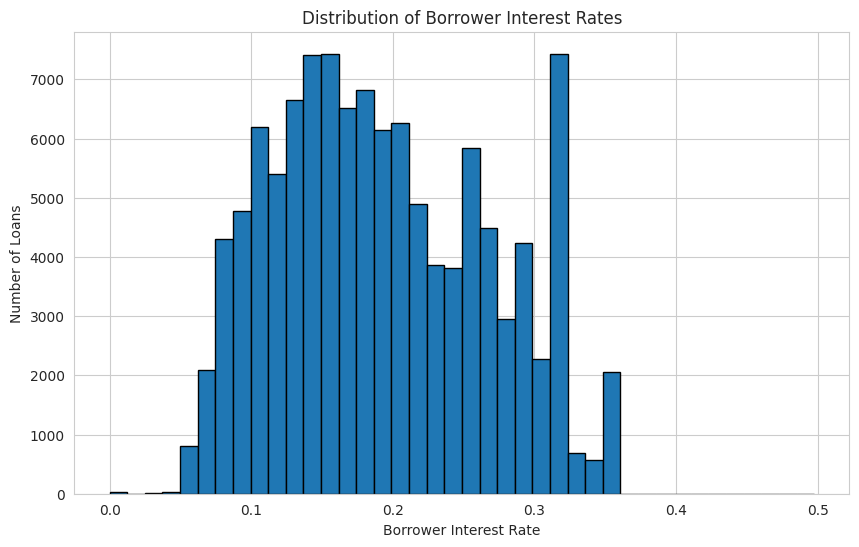

In [28]:
# Plot the distribution of borrower interest rates

plt.figure(figsize=(10, 6))

plt.hist(
    df_core['BorrowerRate'],
    bins=40,
    edgecolor='black'
)

plt.title('Distribution of Borrower Interest Rates')
plt.xlabel('Borrower Interest Rate')
plt.ylabel('Number of Loans')

plt.show()

**Observation:** Most borrower interest rates are concentrated between approximately 0.08 and 0.30.
The distribution shows several noticeable peaks rather than a smooth, symmetric shape.
There is a particularly large concentration around 0.32, while relatively few loans have rates above 0.35.
The distribution also contains a small number of loans with rates close to 0, indicating some unusual observations.

**Assumption:** Loan statuses are likely to be unevenly distributed, with some outcomes occurring much more frequently than others.
The distribution of statuses can provide an initial view of the overall loan portfolio.

**Question:** What are the most common loan statuses in the Prosper dataset?

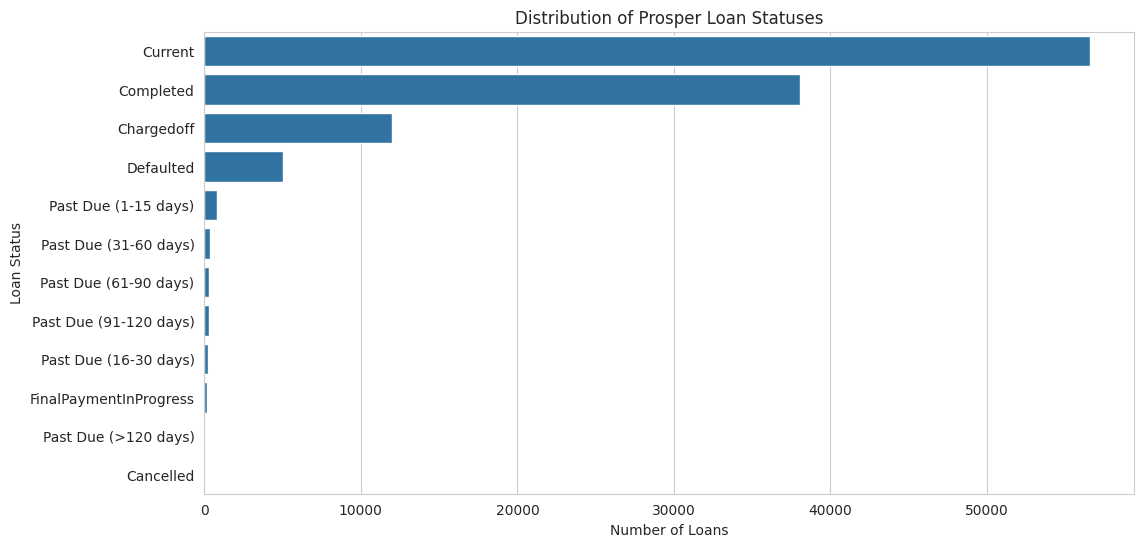

In [29]:
# Plot the distribution of loan statuses

plt.figure(figsize=(12, 6))

status_order = df_core['LoanStatus'].value_counts().index

sns.countplot(
    data=df_core,
    y='LoanStatus',
    order=status_order
)

plt.title('Distribution of Prosper Loan Statuses')
plt.xlabel('Number of Loans')
plt.ylabel('Loan Status')

plt.show()

### Discuss the distribution(s) of your variable(s) of interest. Were there any unusual points? Did you need to perform any transformations?

> Borrower interest rates are concentrated mainly between approximately 8% and 30%, with several noticeable peaks in the distribution. A smaller number of loans have unusually high rates, while very few observations have rates close to 0%. No transformation was required because the original rate distribution was suitable for exploratory visualization.

### Of the features you investigated, were there any unusual distributions? Did you perform any operations on the data to tidy, adjust, or change the form of the data? If so, why did you do this?

> LoanStatus is highly unevenly distributed, with Current and Completed loans accounting for most observations, while Cancelled and long-term Past Due categories are rare. No observations were removed from the core dataset because the selected variables contained no missing values. A separate core dataset was created using the relevant variables to simplify the analysis while retaining all 113,937 loans.

## Bivariate Exploration

> In this section, investigate relationships between pairs of variables in your data. Make sure the variables that you cover here have been introduced in some fashion in the previous section (univariate exploration).


**Observation:** Current loans are the most common category, followed by Completed loans.
Chargedoff and Defaulted loans occur substantially less frequently than Current and Completed loans.
Past Due categories and FinalPaymentInProgress represent only a small fraction of the dataset.
Cancelled loans are extremely rare, indicating that the dataset is dominated by active and completed loans.

**Assumption:** Loan amount may have a relationship with the interest rate assigned to a borrower.
Larger loans may show a different interest-rate pattern compared with smaller loans.

**Question:** How does the borrower interest rate vary with the original loan amount?

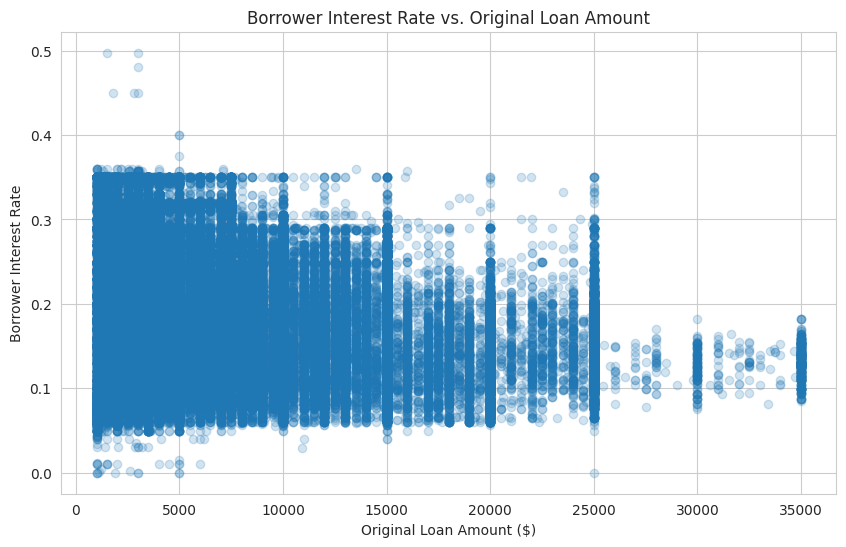

In [30]:
# Plot the relationship between loan amount and borrower interest rate

plt.figure(figsize=(10, 6))

plt.scatter(
    data=df_core,
    x='LoanOriginalAmount',
    y='BorrowerRate',
    alpha=0.2
)

plt.title('Borrower Interest Rate vs. Original Loan Amount')
plt.xlabel('Original Loan Amount ($)')
plt.ylabel('Borrower Interest Rate')

plt.show()

**Observation:** The plot shows a generally negative relationship between loan amount and borrower interest rate.
Higher interest rates are concentrated among smaller loans, while larger loans tend to have lower rates.
The relationship becomes less dense as loan amounts increase, with clear vertical bands caused by commonly used loan amounts.
A few unusually high interest rates occur for relatively small loan amounts, indicating potential outliers.

**Assumption:** Loan term may influence the interest rate assigned to borrowers.
Different repayment periods may therefore have different distributions of borrower rates.

**Question:** How does the distribution of borrower interest rates differ across the three loan terms?

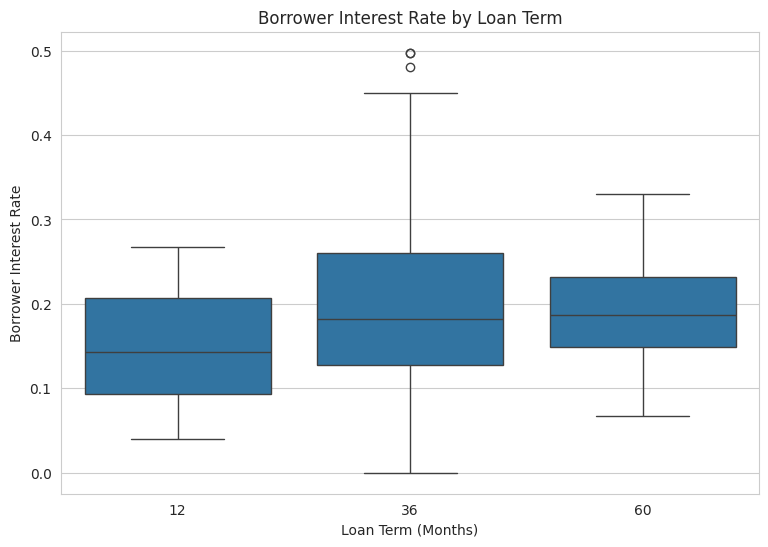

In [31]:
# Plot borrower interest rate distributions across loan terms

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_core,
    x='Term',
    y='BorrowerRate'
)

plt.title('Borrower Interest Rate by Loan Term')
plt.xlabel('Loan Term (Months)')
plt.ylabel('Borrower Interest Rate')

plt.show()

**Observation:** The 36-month term has the highest median borrower interest rate among the three loan terms.
The 12-month loans have the lowest median rate and a relatively narrower overall distribution.
The 36-month category has the widest spread and contains several high-rate outliers near 0.50.
The 60-month loans have a median rate similar to 36-month loans but show a comparatively narrower distribution.

**Assumption:** The distribution of loan outcomes may differ across loan terms.
Comparing loan-status counts across terms can reveal whether certain terms are associated with different loan outcomes.

**Question:** How are loan statuses distributed across the different loan terms?

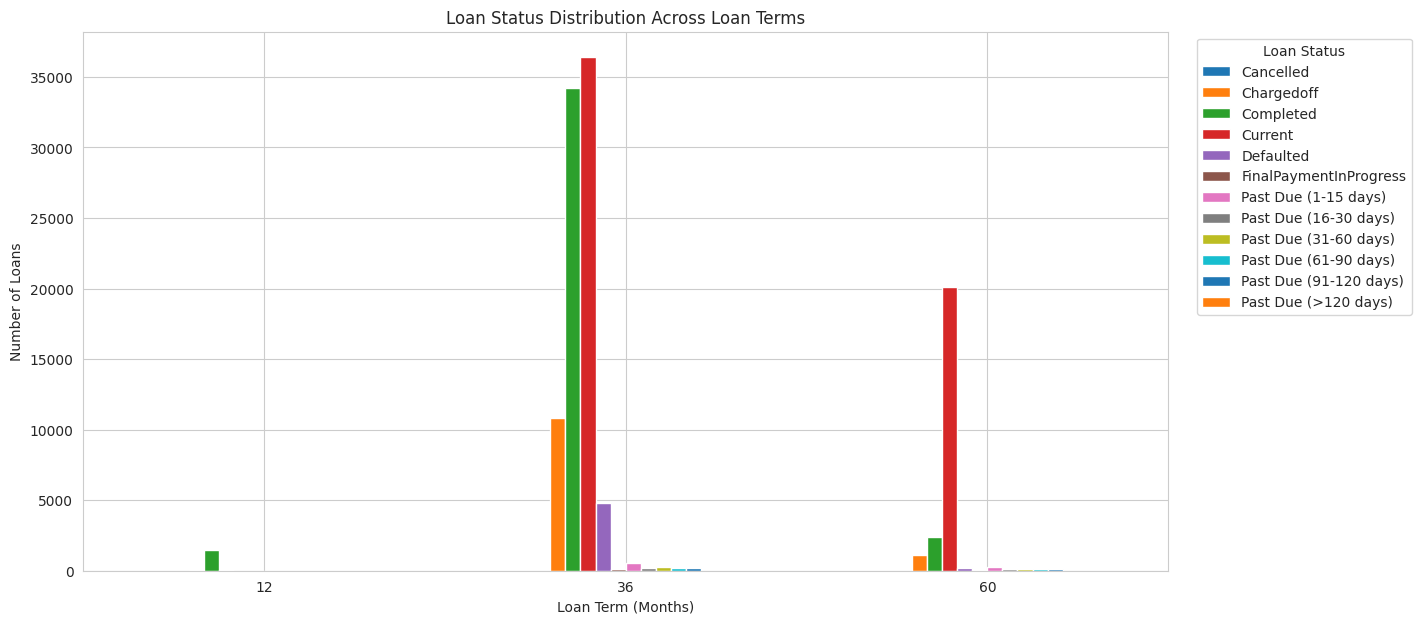

In [32]:
# Create a cross-tabulation of loan status and loan term

status_term = pd.crosstab(
    df_core['Term'],
    df_core['LoanStatus']
)

# Plot the clustered bar chart
status_term.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Loan Status Distribution Across Loan Terms')
plt.xlabel('Loan Term (Months)')
plt.ylabel('Number of Loans')
plt.xticks(rotation=0)
plt.legend(
    title='Loan Status',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.show()

**Observation:** The 36-month term dominates the dataset, with the largest numbers of Current and Completed loans.
The 60-month term has substantially fewer loans but is also dominated by the Current status.
The 12-month term contains relatively few loans and is almost entirely represented by Completed loans.
Chargedoff and Defaulted loans occur mainly among the 36- and 60-month terms.

**Assumption:** Loan amount, borrower interest rate, and loan term may be related to one another.
A correlation heatmap can reveal the strength and direction of these numerical relationships.

**Question:** What relationships exist among the main numerical loan characteristics?

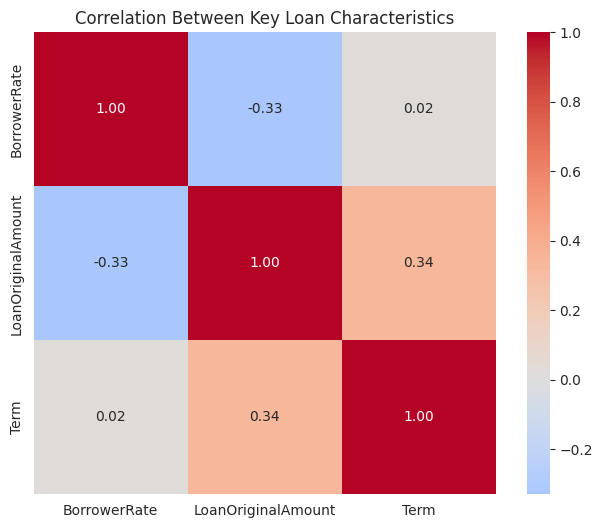

In [33]:
# Select numerical variables for the correlation analysis

numeric_cols = [
    'BorrowerRate',
    'LoanOriginalAmount',
    'Term'
]

correlation_matrix = df_core[numeric_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)

plt.title('Correlation Between Key Loan Characteristics')
plt.show()

**Observation:** BorrowerRate and LoanOriginalAmount show a moderate negative correlation of -0.33.
LoanOriginalAmount and Term have a moderate positive correlation of 0.34.
BorrowerRate and Term have almost no linear relationship, with a correlation of only 0.02.
Overall, loan amount has stronger linear relationships with the other two variables than loan term does.

### Talk about some of the relationships you observed in this part of the investigation. How did the feature(s) of interest vary with other features in the dataset?

> Borrower interest rate generally decreases as the original loan amount increases, showing a moderate negative relationship. Interest rates also vary across loan terms, with 36-month loans having the highest median rate and widest spread. Loan status distributions differ across terms, although 36-month loans dominate the dataset.

### Did you observe any interesting relationships between the other features (not the main feature(s) of interest)?

> Loan term and original loan amount show a moderate positive correlation, indicating that longer-term loans tend to have larger loan amounts. In contrast, loan term and borrower interest rate have almost no linear correlation. The heatmap confirms that loan amount has stronger relationships with the other numerical features than loan term does.

## Multivariate Exploration

> Create plots of three or more variables to investigate your data even
further. Make sure that your investigations are justified, and follow from
your work in the previous sections.


**Assumption:** The relationship between loan amount and borrower interest rate may differ across loan terms.
Separating the data by term may reveal patterns that are hidden when all loans are plotted together.

**Question:** How does the relationship between loan amount and borrower interest rate vary across different loan terms?

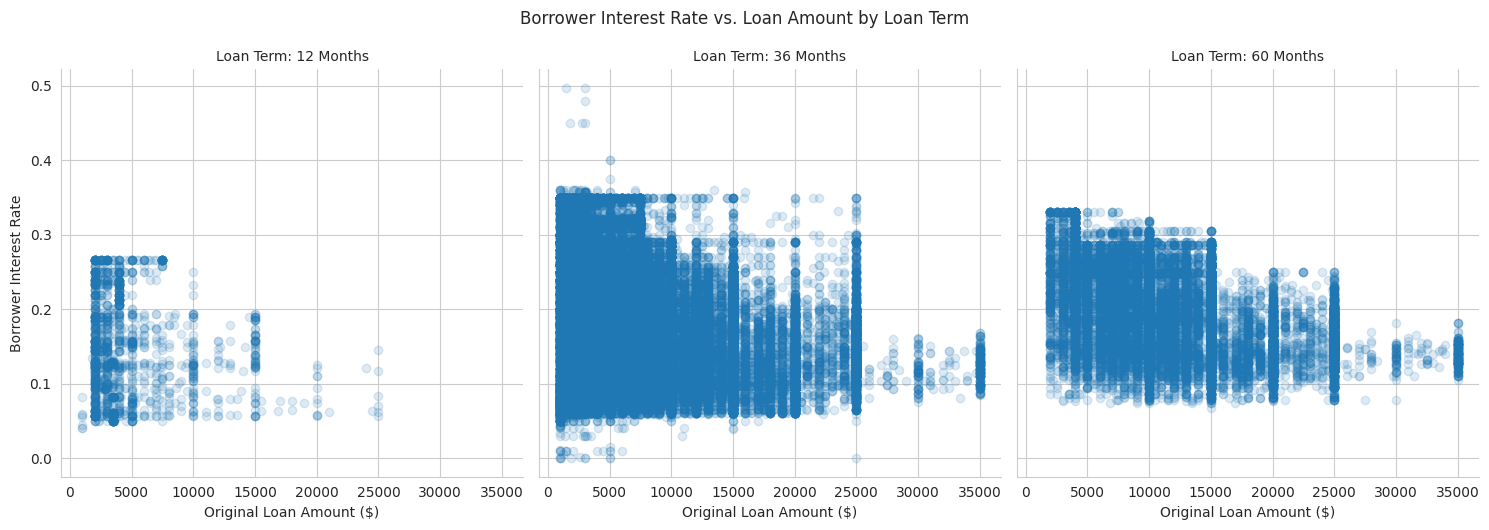

In [34]:
# Create a FacetGrid to compare loan amount and interest rate across terms

g = sns.FacetGrid(
    df_core,
    col='Term',
    height=5,
    aspect=1
)

g.map(
    plt.scatter,
    'LoanOriginalAmount',
    'BorrowerRate',
    alpha=0.15
)

g.set_axis_labels(
    'Original Loan Amount ($)',
    'Borrower Interest Rate'
)

g.set_titles('Loan Term: {col_name} Months')

g.fig.suptitle(
    'Borrower Interest Rate vs. Loan Amount by Loan Term',
    y=1.05
)

plt.show()

**Observation:** The negative relationship between loan amount and borrower interest rate is visible across all three loan terms.
The 36-month loans show the widest range of interest rates and contain the highest-rate observations.
The 12-month loans are concentrated at smaller loan amounts and have a comparatively narrower rate range.
For 60-month loans, interest rates generally decline as loan amounts increase, with higher amounts concentrated around lower rates.

**Assumption:** The relationship between loan amount and interest rate may vary according to borrower home ownership and loan term.
Using color and marker style may reveal differences that are not visible in a basic two-variable scatter plot.

**Question:** How do home ownership and loan term influence the relationship between original loan amount and borrower interest rate?

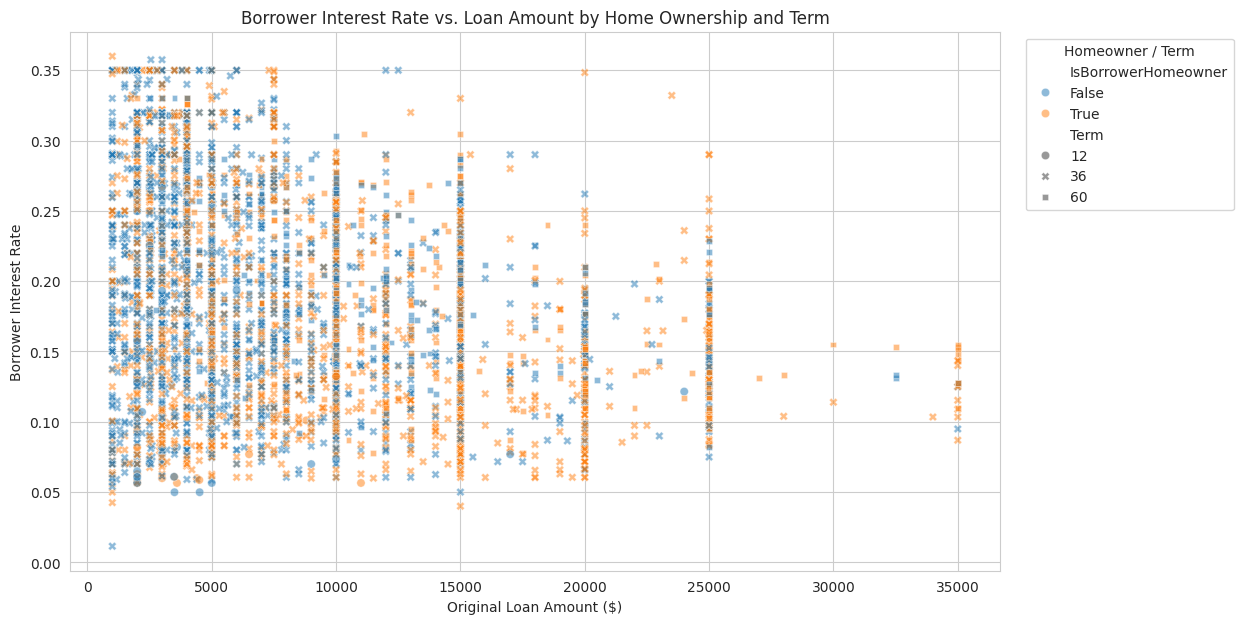

In [35]:
# Create a sample for clearer visualization
# Sampling reduces overplotting while preserving the overall patterns.

plot_sample = df_core.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_sample,
    x='LoanOriginalAmount',
    y='BorrowerRate',
    hue='IsBorrowerHomeowner',
    style='Term',
    alpha=0.5
)

plt.title('Borrower Interest Rate vs. Loan Amount by Home Ownership and Term')
plt.xlabel('Original Loan Amount ($)')
plt.ylabel('Borrower Interest Rate')

plt.legend(
    title='Homeowner / Term',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.show()

**Observation:** The negative relationship between loan amount and borrower interest rate remains visible across the encoded groups.
Homeowners and non-homeowners show substantial overlap, suggesting home ownership alone does not strongly separate the rate patterns.
The 36-month loans are the most widely distributed and appear across most combinations of loan amounts and interest rates.
Higher loan amounts are generally associated with lower interest rates, while smaller loans show greater variation in rates.

### Talk about some of the relationships you observed in this part of the investigation. Were there features that strengthened each other in terms of looking at your feature(s) of interest?

> The multivariate analysis strengthened the observed negative relationship between loan amount and borrower interest rate across different loan terms. The Facet Plot showed that this pattern exists for 12-, 36-, and 60-month loans, while the multiple-encoding plot showed that home ownership does not substantially change this relationship.

### Were there any interesting or surprising interactions between features?

> The 36-month loans showed the widest range of interest rates and the highest concentration of observations. Homeowners and non-homeowners displayed considerable overlap in interest rates across loan amounts. Overall, loan term appeared more influential than home ownership in differentiating the observed interest-rate patterns.

## Conclusions
>The exploratory analysis of the Prosper Loan dataset revealed several important patterns:

>- Borrower interest rates are concentrated mainly between 8% and 30%, with several noticeable peaks and a small number of unusually high rates.
>- Current and Completed loans make up the majority of the dataset, while Cancelled and highly delinquent loan statuses are relatively rare.
>- Borrower interest rate has a moderate negative relationship with the original loan amount, with larger loans generally associated with lower interest rates.
>- Interest-rate distributions differ across loan terms. The 36-month loans have the highest median rate and the widest spread of interest rates.
>- Loan amount and loan term have a moderate positive relationship, while loan term and borrower rate show almost no linear relationship.
>- The multivariate analysis confirmed that the negative relationship between loan amount and interest rate remains across different loan terms.
>- Home ownership showed considerable overlap between borrowers, suggesting that it does not strongly distinguish interest-rate patterns.
>- Overall, loan amount and loan term provided more noticeable patterns in explaining borrower interest rates than home ownership.

>The analysis progressed from univariate distributions to bivariate relationships and finally to multivariate interactions. Missing values were examined carefully, and a focused core dataset was created without removing any of the 113,937 observations. The visualizations helped identify the major patterns that can be developed further in the explanatory analysis.
